# 02-逻辑门、Digital 仿真与 PCB 制作

> 从布尔逻辑出发，用开关和灯泡理解逻辑门，再用 Digital 软件完成仿真，最后认识 EDA 原理图与实物 PCB 的制作流程。

## 1. 本篇学习范围

本篇对应课程视频 **18—28**，讲义《自己动手做台计算机》第 **37—47 页**。学习主线是：

1. 把“通电/断电”抽象为二进制的 1/0；
2. 用布尔运算描述开关组合；
3. 掌握与门、或门、非门、异或门及真值表；
4. 使用 Digital 进行逻辑门仿真，观察输入改变时输出如何变化；
5. 了解从逻辑电路到 EDA 原理图、元件选择和实体 PCB 的基本流程。

**边界说明：**讲义第 48 页开始进入 ALU、半加器等内容，属于第 03 篇，本篇不展开。

## 2. 布尔运算与逻辑电路

计算机底层的很多判断都可以归结为两个状态：

- **0**：低电平、断开、条件不成立；
- **1**：高电平、导通、条件成立。

布尔运算处理的不是连续数值，而是只有 0 和 1 的逻辑量。逻辑门把一个或多个输入转换为一个输出，输出结果只由当前输入组合决定。

### 2.1 开关类比

可以把输入看成开关，把输出看成灯泡：开关闭合表示输入为 1，断开表示输入为 0；电流通路形成时灯泡亮，表示输出为 1。不同的开关连接方式，就对应不同的逻辑门。

这种类比帮助我们先理解“逻辑关系”，再去看晶体管、继电器或集成芯片内部的具体实现。

## 3. 逻辑门的统一读法：输入、输出、真值表

分析一个逻辑门时，可以固定按下面的顺序：

1. 写出所有输入变量，例如 `A`、`B`；
2. 列出输入的全部组合；
3. 根据电路关系计算输出 `Y`；
4. 用真值表检查每一种情况。

两个输入共有 `2² = 4` 种组合，四行必须完整写出：

| A | B |
|---:|---:|
| 0 | 0 |
| 0 | 1 |
| 1 | 0 |
| 1 | 1 |

真值表把“看图猜结果”变成可验证的规则。搭建 Digital 电路时，也应先写真值表，再接线和测试。

## 4. 与门 AND：所有条件同时满足

与门有两个输入 `A`、`B` 和一个输出 `Y`。只有两个输入都为 1 时，输出才为 1。

布尔表达式：

```text
Y = A · B
```

这里的点号表示逻辑与，不是普通十进制乘法；由于输入只有 0/1，写成乘法形式也很直观。用开关类比，就是两个开关串联：任意一个断开，电流都无法到达输出。

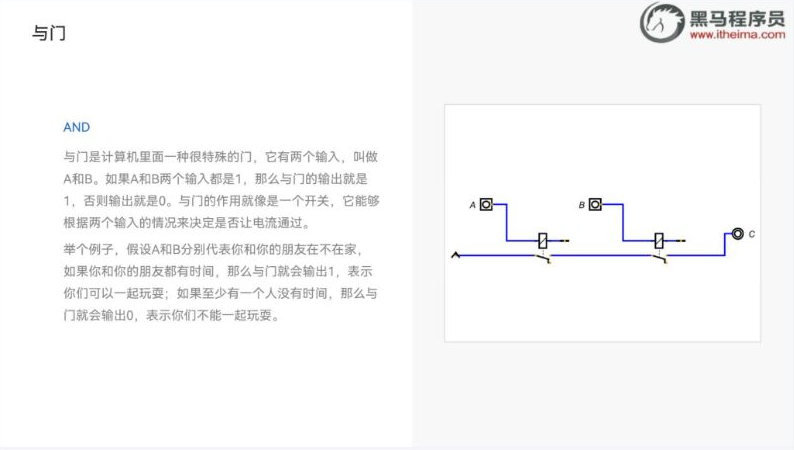

| A | B | Y = A·B |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 0 |
| 1 | 0 | 0 |
| 1 | 1 | 1 |

**记忆：**与门看“全体”，有一个 0，结果就是 0。

## 5. 或门 OR：至少一个条件满足

或门的输出在任意一个输入为 1 时就是 1；只有所有输入都为 0 时，输出才为 0。

布尔表达式：

```text
Y = A + B
```

加号表示逻辑或，不代表普通算术加法。用开关类比，就是两个开关并联：只要任意一条支路导通，输出端就有电流。

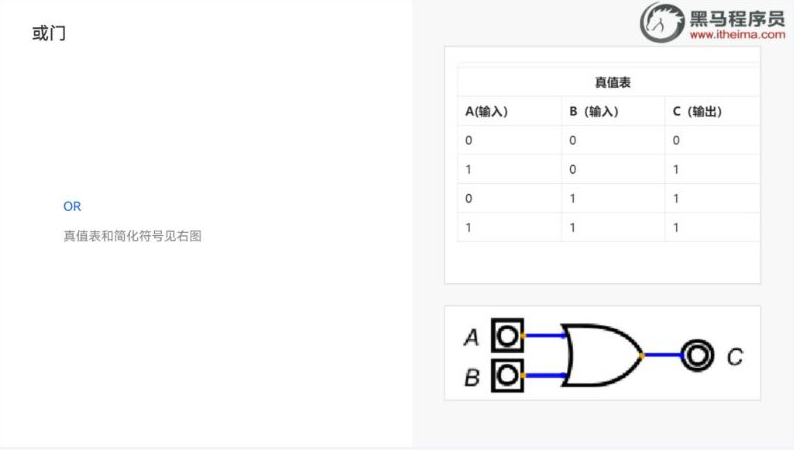

| A | B | Y = A+B |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 1 |

**记忆：**或门看“有没有”，有一个 1，结果就是 1。

## 6. 非门 NOT：把输入反相

非门只有一个输入 `A` 和一个输出 `Y`，输出永远与输入相反。

布尔表达式：

```text
Y = ¬A
```

也可以写成 `Y = NOT(A)`。非门符号的输出端通常带一个小圆点，用来表示反相。

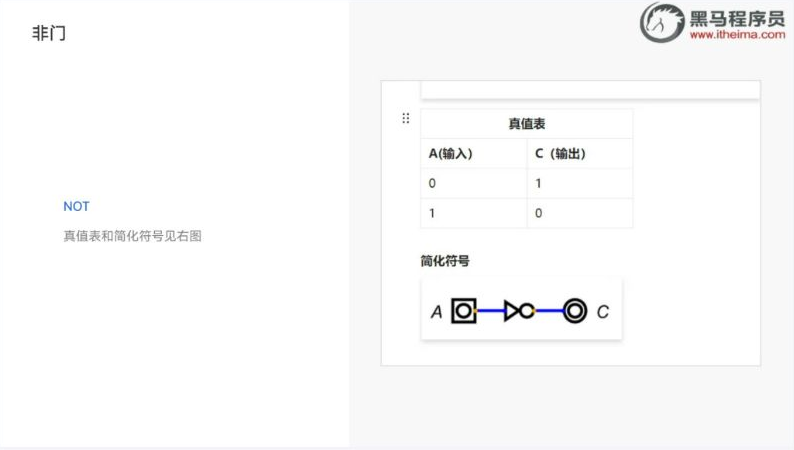

| A | Y = ¬A |
|---:|---:|
| 0 | 1 |
| 1 | 0 |

非门是组合逻辑中最基本的翻转器：它不增加输入数量，只改变逻辑状态。

## 7. 异或门 XOR：输入不同才为 1

异或门的输出在两个输入不相同时为 1，在两个输入相同时为 0。

布尔表达式：

```text
Y = A ⊕ B
```

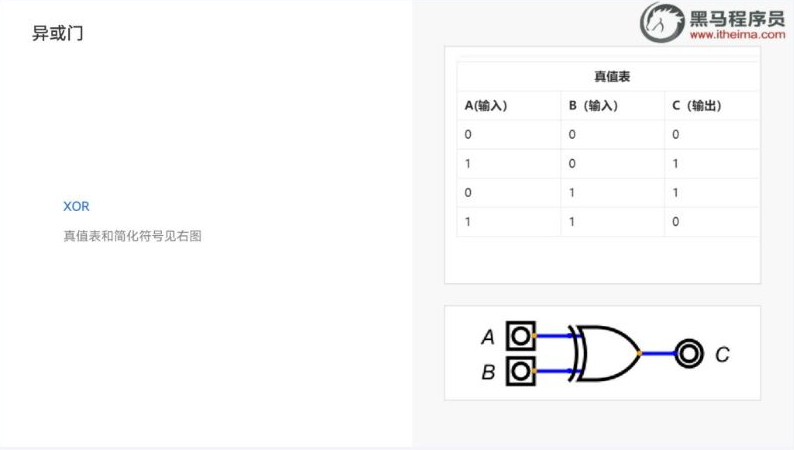

| A | B | Y = A⊕B |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

异或经常用来表达“是否不同”“奇偶性是否改变”等条件。它与或门的区别是：两个输入都为 1 时，或门输出 1，而异或门输出 0。

## 8. 四种逻辑门的符号、表达式和对比

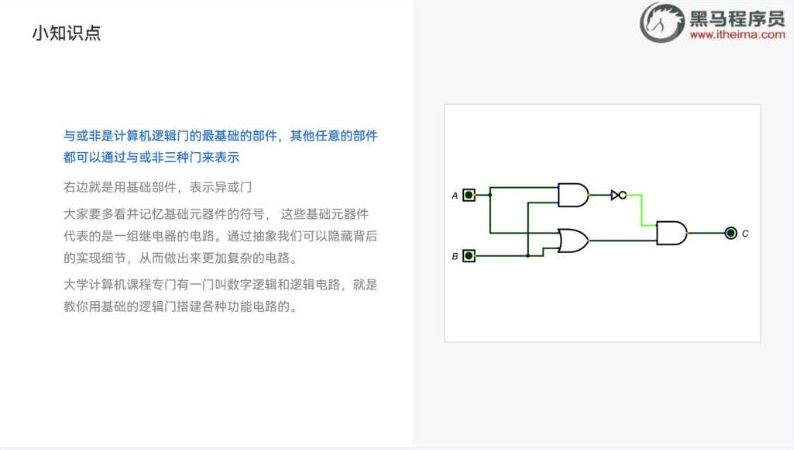

| 逻辑门 | 符号表达式 | 输出为 1 的条件 | 典型开关类比 |
|---|---|---|---|
| AND 与门 | `A·B` | A、B 全为 1 | 串联 |
| OR 或门 | `A+B` | A、B 至少一个为 1 | 并联 |
| NOT 非门 | `¬A` | A 为 0 | 反相 |
| XOR 异或门 | `A⊕B` | A、B 不同 | “不同才亮” |

### 8.1 一个容易混淆的点

逻辑或 `A+B` 和异或 `A⊕B` 只有在 `A、B` 不同时结果相同；当 `A=B=1` 时，逻辑或仍为 1，而异或为 0。

### 8.2 为什么要使用抽象符号

逻辑门内部可以由继电器、晶体管或其他器件实现。使用统一符号后，设计者可以暂时隐藏底层元件，只关心输入输出关系，再把多个门组合成更复杂的电路。

## 9. Digital 软件：从真值表到可运行的电路

课程视频 19—21 介绍 Digital 的配置、与门搭建和常见软件小问题。Digital 是用于绘制和仿真数字逻辑电路的工具，适合用来验证门电路的输入输出关系。

### 9.1 推荐操作顺序

1. 按课程视频完成软件配置，确认程序能正常启动；
2. 新建电路，放置输入开关、逻辑门和输出指示灯；
3. 按信号方向连接导线，避免输入端悬空；
4. 逐项改变输入，观察输出灯的状态；
5. 对照真值表，把所有输入组合测试一遍；
6. 保存工程，给电路和输入输出端写清楚名称。

仿真不是只看某一次灯亮不亮，而是验证四行真值表是否全部符合。

## 10. 在 Digital 中搭建四种基础门

课程视频 20、22、23、24 分别演示了与门、或门、非门和异或门的搭建。可以按照同一套模板练习。

- **输入端：**为每个输入放置一个开关或输入元件，并标记 `A`、`B`；
- **逻辑门：**选择对应的 AND、OR、NOT 或 XOR 元件；
- **输出端：**接一个灯或输出探针，标记 `Y`；
- **连线：**从输入端到逻辑门，再从逻辑门到输出端；
- **验证：**按真值表依次切换输入。

| 电路 | 应重点检查的情况 | 预期输出 |
|---|---|---:|
| AND | `A=1,B=1` | 1 |
| OR | `A=0,B=0` | 0 |
| NOT | 输入从 0 切换到 1 | 输出从 1 切换到 0 |
| XOR | `A=B` 与 `A≠B` 各测一次 | 前者 0，后者 1 |

完成后可以把四个门放在同一张工程图中，作为本篇的综合练习。

## 11. 用与、或、非实现更复杂的逻辑

课程视频 26 强调：**任意逻辑电路都可以通过与、或、非电路组合实现。**重点是理解“分解—组合”的设计方法。

例如，要求“开关 A 和 B 都打开，或者开关 C 打开时，灯 Y 点亮”：

```text
Y = (A · B) + C
```

搭建步骤：先用一个 AND 得到 `A·B`，再用一个 OR 把 `A·B` 与 `C` 合并，OR 的输出就是 `Y`。先写出条件，再逐层实现子表达式，最后检查整体真值表。电路越复杂，越要给中间信号命名，例如 `X=A·B`、`Y=X+C`。

## 12. EDA 原理图、元件选择与 PCB 制作

课程视频 27—28 和讲义第 47 页把抽象逻辑门落到实体电路：先画原理图，再选择器件，最后形成可制作的电路板。

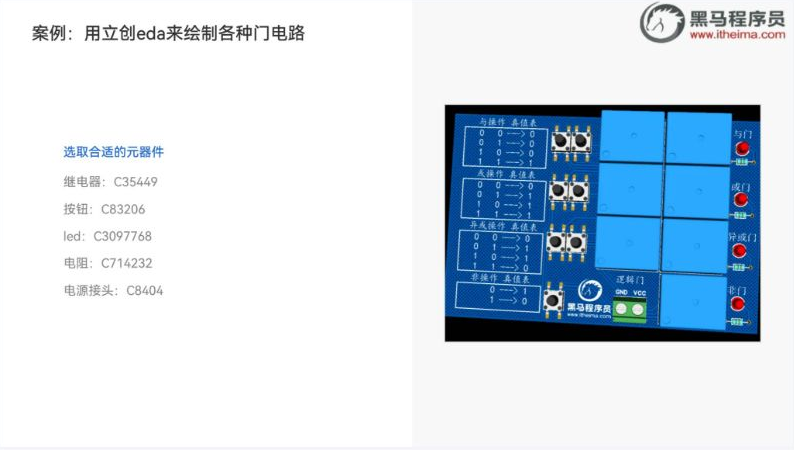

### 12.1 基本流程

1. 确定逻辑功能：先用真值表和逻辑门表达式确认电路；
2. 绘制原理图：放置输入、逻辑门、输出和供电连接；
3. 选择封装和元件：让原理图器件对应实际可采购、可焊接的零件；
4. 检查连接关系：确认电源、地、输入、输出和器件引脚没有遗漏；
5. 生成 PCB 设计：根据原理图安排元件和走线；
6. 检查实物板：对照原理图识别元件位置和连接。

### 12.2 讲义中列出的器件

| 器件 | 课程资料中的元件编号 | 用途理解 |
|---|---|---|
| 继电器 | `C35449` | 用开关动作实现控制 |
| 按钮 | `C83206` | 提供人工输入 |
| LED | `C3097768` | 显示逻辑输出状态 |
| 电阻 | `C714232` | 限流、保护 LED 等器件 |
| 电源接头 | `C8404` | 接入供电 |

资料在这一部分重点展示原理图、元件选择和实体板示例；具体 PCB 线宽、间距和加工参数应以所用 EDA 工具及制造商规则为准。

## 13. 常见问题与排查方法

课程视频 21 提醒了软件配置和仿真中的小问题。遇到“输出不对”时，可以按信号链逐层排查：

### 软件与工程问题

- 软件无法启动：检查配置是否按课程要求完成，重新打开工程；
- 元件找不到：确认当前元件库、搜索名称和门类型；
- 工程没有保存：先保存到明确的课程目录，再继续修改。

### 电路连接问题

- 输入端悬空：每个输入都必须接到明确的 0 或 1；
- 导线没有真正连接：检查交叉处是否有连接点，必要时重新布线；
- 输入输出接反：沿着“输入 → 逻辑门 → 输出”的方向检查；
- 把 OR 当成 XOR：重点测试 `A=1、B=1`；
- 只测试一组输入：重新对照完整真值表逐行验证。

实物电路还要检查供电极性、LED 方向、电阻是否串联限流、继电器和按钮的引脚定义。仿真正确只能说明逻辑关系正确，不能替代上电前的硬件检查。

## 14. 一页复习表

| 知识点 | 关键结论 |
|---|---|
| 逻辑状态 | 0/1 可对应断开/导通、低电平/高电平 |
| AND | 全 1 才输出 1，`Y=A·B` |
| OR | 有 1 就输出 1，`Y=A+B` |
| NOT | 输出与输入相反，`Y=¬A` |
| XOR | 输入不同输出 1，相同输出 0，`Y=A⊕B` |
| 真值表 | 穷举所有输入组合，用于验证电路 |
| Digital | 先搭门电路，再按真值表逐行仿真 |
| 组合逻辑 | 先写条件和表达式，再逐层连接门电路 |
| PCB 流程 | 原理图 → 元件/封装 → 布局布线 → 实物板 |

## 15. 自测题

1. 与门和或门的输出条件分别是什么？
2. 写出 XOR 的四行真值表，并指出它与 OR 的差别。
3. 对表达式 `Y=(A·B)+C`，需要哪些基础逻辑门？
4. 在 Digital 中，为什么要把所有输入组合都测试一遍？
5. 从原理图到实体 PCB，至少要经历哪些主要步骤？

### 参考答案

1. AND 要求所有输入为 1；OR 只要任意一个输入为 1。
2. XOR 的输出依次为 `0、1、1、0`；与 OR 的差别在 `A=B=1` 时，XOR 为 0、OR 为 1。
3. 一个 AND 和一个 OR；先算 `A·B`，再与 `C` 做 OR。
4. 因为真值表描述的是全部输入组合，只测一组不能证明逻辑门完全正确。
5. 确定功能和真值表、绘制原理图、选择器件/封装、布局布线、规则检查并制作实物板。

## 16. 与原课程资料对应关系

| 本篇内容 | 视频 | 讲义页码 |
|---|---|---:|
| 逻辑门电路、布尔逻辑 | 18 | 37—38 |
| Digital 配置、软件问题 | 19、21 | 相关操作配合 39—45 |
| 与门 | 20 | 39—41 |
| 或门 | 22 | 42 |
| 非门 | 23 | 43—44 |
| 异或门 | 24 | 45 |
| 逻辑门符号、组合思想 | 25、26、27 | 46 |
| EDA 原理图、器件与 PCB | 28 | 47 |

**资料来源：**《自己动手做台计算机》课程，百度网盘分享链接：`https://pan.baidu.com/s/1RLiC8gC1sXTu7EgkQs9oHw?pwd=6633`，提取码：`6633`。本篇按课程视频 18—28 和讲义 37—47 页整理。